# Эксперименты: NSGA-II против взвешенной суммы и случайного поиска

**Методика** повторяет ЛР1–ЛР2: 20 независимых запусков с `seed = 1000, …, 1019`, единый бюджет в 1000 обучений модели на запуск, все параметры кроме варьируемого фактора совпадают с базовой конфигурацией.

Сравниваются пять серий:

| Серия | Метод | Отличие от базовой |
|---|---|---|
| `NSGAII_base` | NSGA-II | — |
| `NSGAII_small_pop` | NSGA-II | размер популяции 30 вместо 60 |
| `NSGAII_high_mutation` | NSGA-II | вероятность мутации гена 0.3 вместо 0.15 |
| `WeightedSum` | ГА над свёрткой $0.6\tilde f_1 + 0.2\tilde f_2 + 0.2\tilde f_3$ | тот же бюджет и операторы |
| `RandomSearch` | случайная выборка генотипов | тот же бюджет |

Качество результата запуска оценивается гиперобъёмом фронта Парето архива всех оценённых решений относительно фиксированной опорной точки (раздел «Настройка гиперпараметров» первого ноутбука). Гиперобъём учитывает и близость к истинному фронту, и равномерность его заполнения, поэтому корректно сравнивает методы, возвращающие разное число решений.

In [1]:
%matplotlib inline

import json
from dataclasses import asdict
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

import tuning_nsga2 as tn

RESULTS_DIR = Path("results")
CONFIGS_DIR = Path("configs")
PLOTS_DIR = Path("plots")
for directory in (RESULTS_DIR, CONFIGS_DIR, PLOTS_DIR):
    directory.mkdir(exist_ok=True)
SEEDS = list(range(1000, 1020))
data = tn.generate_data()


def save_json(payload: dict, path: Path) -> None:
    path.parent.mkdir(parents=True, exist_ok=True)
    path.write_text(json.dumps(payload, ensure_ascii=False, indent=2) + "\n", encoding="utf-8")


def run_series(name: str, make_config, method: str) -> list[dict]:
    rows = []
    for seed in SEEDS:
        config = make_config(seed)
        result = tn.run_random_search(data, config) if method == "random_search" else tn.run_method(data, config)
        front = np.array(result["front_objectives"])
        rows.append({
            "seed": seed,
            "hypervolume": result["hypervolume"],
            "front_size": result["front_size"],
            "best_error": float(front[:, 0].min()),
            "min_cost": float(front[:, 1].min()),
            "min_params": int(front[:, 2].min()),
            "n_evals": result["n_evals"],
            "elapsed_seconds": round(result["elapsed_seconds"], 3),
            "mean_eval_ms": round(result["mean_eval_seconds"] * 1000, 2),
            "history_evals": result["history_evals"],
            "history_hv": result["history_hv"],
        })
        print(f"{name} seed={seed}: hv={result['hypervolume']:.4g} front={result['front_size']}", flush=True)
    return rows

print("setup ok")

setup ok


## Запуск серий

Каждая серия выполняет 20 запусков и сохраняет построчные результаты в `results/<серия>.csv`, конфигурации — в `configs/`, полные истории и фронты — в `results/all_results.json`. Полный прогон занимает около 15 минут.

In [2]:
base = tn.GAConfig(seed=0)
save_json({**asdict(base), "method": "nsga2", "seeds": SEEDS}, CONFIGS_DIR / "base.json")

series = {
    "NSGAII_base": (lambda seed: tn.GAConfig(seed=seed, method="nsga2"), "nsga2"),
    "NSGAII_small_pop": (lambda seed: tn.GAConfig(seed=seed, population_size=30, method="nsga2"), "nsga2"),
    "NSGAII_high_mutation": (lambda seed: tn.GAConfig(seed=seed, mutation_prob=0.3, method="nsga2"), "nsga2"),
    "WeightedSum": (lambda seed: tn.GAConfig(seed=seed, method="weighted_sum"), "weighted_sum"),
    "RandomSearch": (lambda seed: tn.GAConfig(seed=seed), "random_search"),
}

all_results: dict[str, list[dict]] = {}
for name, (make_config, method) in series.items():
    rows = run_series(name, make_config, method)
    all_results[name] = rows
    table = pd.DataFrame([{k: v for k, v in row.items() if k not in ("history_evals", "history_hv")} for row in rows])
    table.to_csv(RESULTS_DIR / f"{name}.csv", index=False)
    config = make_config(SEEDS[0])
    save_json({**asdict(config), "method": method, "seeds": SEEDS}, CONFIGS_DIR / f"{name}.json")
    print(f"=== {name}: mean hv = {table['hypervolume'].mean():.4g} ===", flush=True)

save_json(all_results, RESULTS_DIR / "all_results.json")

NSGAII_base seed=1000: hv=1.376e+08 front=108


NSGAII_base seed=1001: hv=1.376e+08 front=42


NSGAII_base seed=1002: hv=1.369e+08 front=97


NSGAII_base seed=1003: hv=1.37e+08 front=110


NSGAII_base seed=1004: hv=1.376e+08 front=126


NSGAII_base seed=1005: hv=1.368e+08 front=73


... (95 outputs left out)

RandomSearch seed=1017: hv=1.361e+08 front=13


RandomSearch seed=1018: hv=1.367e+08 front=13


RandomSearch seed=1019: hv=1.37e+08 front=21


=== RandomSearch: mean hv = 1.365e+08 ===


## Статистика серий

Для каждой серии: лучший, средний, медианный, стандартное отклонение и худший гиперобъём, средний размер фронта и среднее время обучения модели.

In [3]:
summary_rows = []
for name, rows in all_results.items():
    hv = pd.Series([r["hypervolume"] for r in rows])
    summary_rows.append({
        "method": name,
        "best": hv.max(),
        "mean": hv.mean(),
        "median": hv.median(),
        "std": hv.std(),
        "worst": hv.min(),
        "mean_front_size": float(np.mean([r["front_size"] for r in rows])),
        "mean_run_seconds": float(np.mean([r["elapsed_seconds"] for r in rows])),
        "mean_eval_ms": float(np.mean([r["mean_eval_ms"] for r in rows])),
    })
summary = pd.DataFrame(summary_rows)
summary.to_csv(RESULTS_DIR / "summary.csv", index=False)
save_json(summary.to_dict(orient="records"), RESULTS_DIR / "summary.json")
summary

,method,best,mean,median,std,worst,mean_front_size,mean_run_seconds,mean_eval_ms
0,NSGAII_base,1.376197e+08,1.372893e+08,1.374801e+08,334116.990796,1.367688e+08,88.35,5.42920,6.1130
1,NSGAII_small_pop,1.377369e+08,1.370649e+08,1.372084e+08,630423.329014,1.355618e+08,118.50,4.52985,5.0535
2,NSGAII_high_mutation,1.376206e+08,1.373584e+08,1.375451e+08,369111.067224,1.363186e+08,111.70,5.43935,5.6825
3,WeightedSum,1.373915e+08,1.369351e+08,1.372055e+08,692027.399447,1.343786e+08,32.10,7.40635,8.4350
4,RandomSearch,1.372544e+08,1.365403e+08,1.365927e+08,400312.684541,1.355947e+08,13.85,18.50200,18.2690


## Сходимость: гиперобъём от числа оцениваний

Линия — средний гиперобъём архива по 20 запускам, полоса — ±1 стандартное отклонение. Истории приводятся к общей сетке по числу оцениваний линейной интерполяцией.

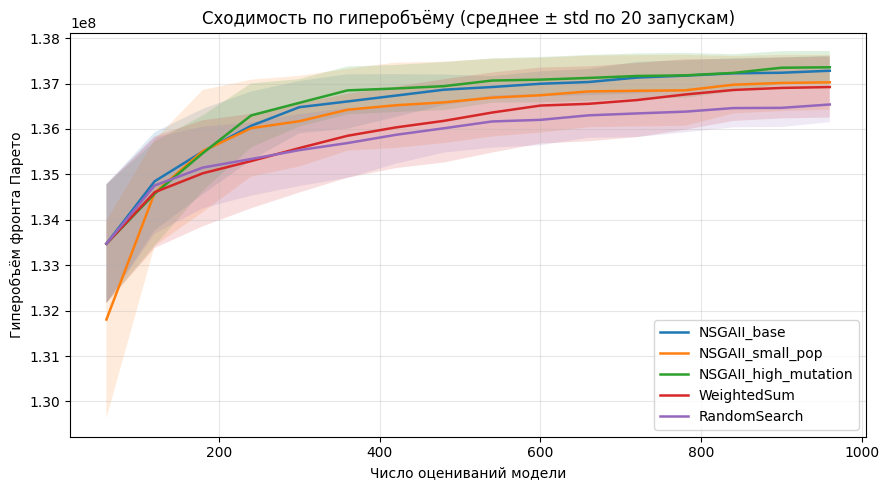

In [4]:
grid = np.arange(base.population_size, base.budget + 1, base.population_size, dtype=float)

fig, ax = plt.subplots(figsize=(9, 5))
for name, rows in all_results.items():
    curves = []
    for row in rows:
        curves.append(np.interp(grid, np.asarray(row["history_evals"], dtype=float), np.asarray(row["history_hv"], dtype=float)))
    curves = np.array(curves)
    mean, std = curves.mean(axis=0), curves.std(axis=0)
    ax.plot(grid, mean, label=name, linewidth=1.8)
    ax.fill_between(grid, mean - std, mean + std, alpha=0.15)
ax.set_xlabel("Число оцениваний модели")
ax.set_ylabel("Гиперобъём фронта Парето")
ax.set_title("Сходимость по гиперобъёму (среднее ± std по 20 запускам)")
ax.grid(alpha=0.3)
ax.legend()
fig.tight_layout()
fig.savefig(PLOTS_DIR / "convergence.png", dpi=150)
plt.show()

## Сравнение итоговых гиперобъёмов

/var/folders/tr/m23x157946jg361ly70phfk40000gn/T/ipykernel_27830/3013854153.py:3: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  ax.boxplot(values, labels=list(all_results), showmeans=True)


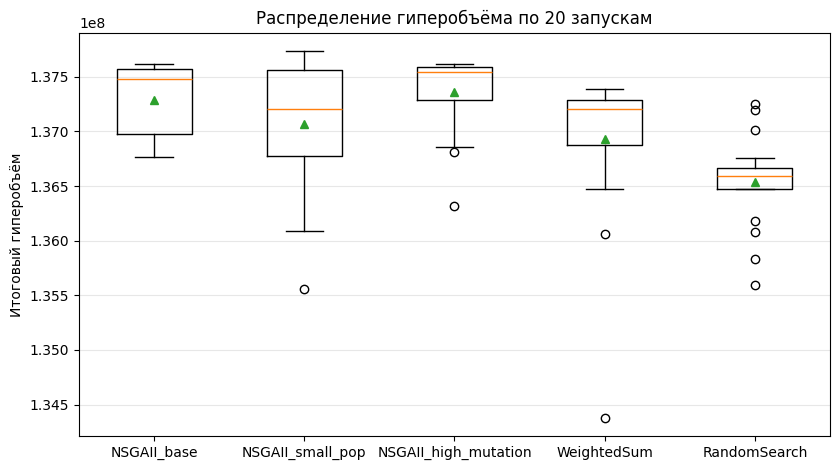

In [5]:
fig, ax = plt.subplots(figsize=(8.5, 4.8))
values = [[r["hypervolume"] for r in all_results[name]] for name in all_results]
ax.boxplot(values, labels=list(all_results), showmeans=True)
ax.set_ylabel("Итоговый гиперобъём")
ax.set_title("Распределение гиперобъёма по 20 запускам")
ax.grid(alpha=0.3, axis="y")
fig.tight_layout()
fig.savefig(PLOTS_DIR / "comparison.png", dpi=150)
plt.show()

## Блок-схема NSGA-II

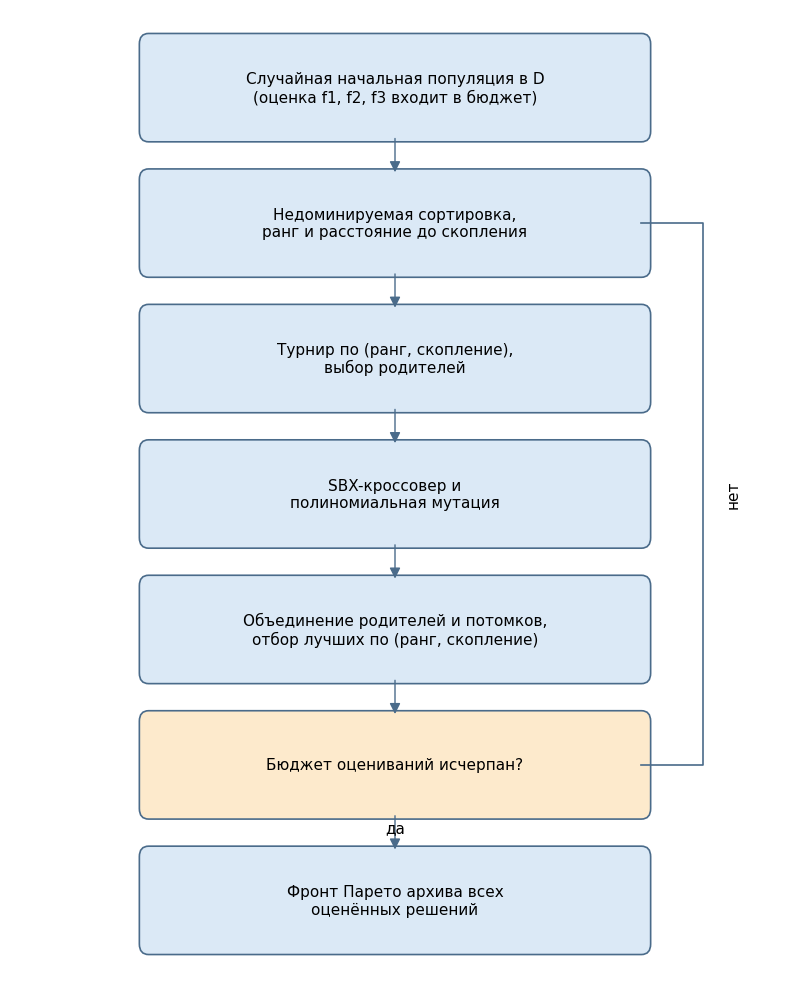

In [6]:
from matplotlib.patches import FancyArrowPatch, FancyBboxPatch

steps = [
    "Случайная начальная популяция в D\n(оценка f1, f2, f3 входит в бюджет)",
    "Недоминируемая сортировка,\nранг и расстояние до скопления",
    "Турнир по (ранг, скопление),\nвыбор родителей",
    "SBX-кроссовер и\nполиномиальная мутация",
    "Объединение родителей и потомков,\nотбор лучших по (ранг, скопление)",
    "Бюджет оцениваний исчерпан?",
    "Фронт Парето архива всех\nоценённых решений",
]

fig, ax = plt.subplots(figsize=(8, 10))
ax.axis("off")
centers = []
for i, text in enumerate(steps):
    y = 1 - i * 0.155
    centers.append(y)
    box = FancyBboxPatch((0.18, y - 0.05), 0.64, 0.1,
                         boxstyle="round,pad=0.012",
                         facecolor="#dbe9f6" if i != 5 else "#fdeacc",
                         edgecolor="#4a6b8a", linewidth=1.2)
    ax.add_patch(box)
    ax.text(0.5, y, text, ha="center", va="center", fontsize=11)
for i in range(len(steps) - 1):
    arrow = FancyArrowPatch((0.5, centers[i] - 0.055), (0.5, centers[i + 1] + 0.055),
                            arrowstyle="-|>", mutation_scale=16, color="#4a6b8a")
    ax.add_patch(arrow)
loop = FancyArrowPatch((0.82, centers[5]), (0.9, centers[5]),
                       arrowstyle="-", color="#4a6b8a", linewidth=1.2)
ax.plot([0.82, 0.9, 0.9, 0.82], [centers[5], centers[5], centers[1], centers[1]], color="#4a6b8a", linewidth=1.2)
ax.text(0.93, (centers[1] + centers[5]) / 2, "нет", fontsize=11, rotation=90, va="center")
ax.text(0.5, (centers[5] + centers[6]) / 2, "да", fontsize=11, ha="center")
ax.set_xlim(0, 1)
ax.set_ylim(centers[-1] - 0.09, centers[0] + 0.09)
fig.tight_layout()
fig.savefig(PLOTS_DIR / "algorithm_flowchart.png", dpi=150)
plt.show()

## Фронт лучшего запуска и три характерных решения

Из серии `NSGAII_base` берётся запуск с максимальным гиперобъёмом. На проекциях его фронта отмечены три компромисса — «быстрое», «сбалансированное» и «точное» — и сохраняются в `results/representative_solutions.csv` в декодированной форме вместе с фактическим временем обучения.

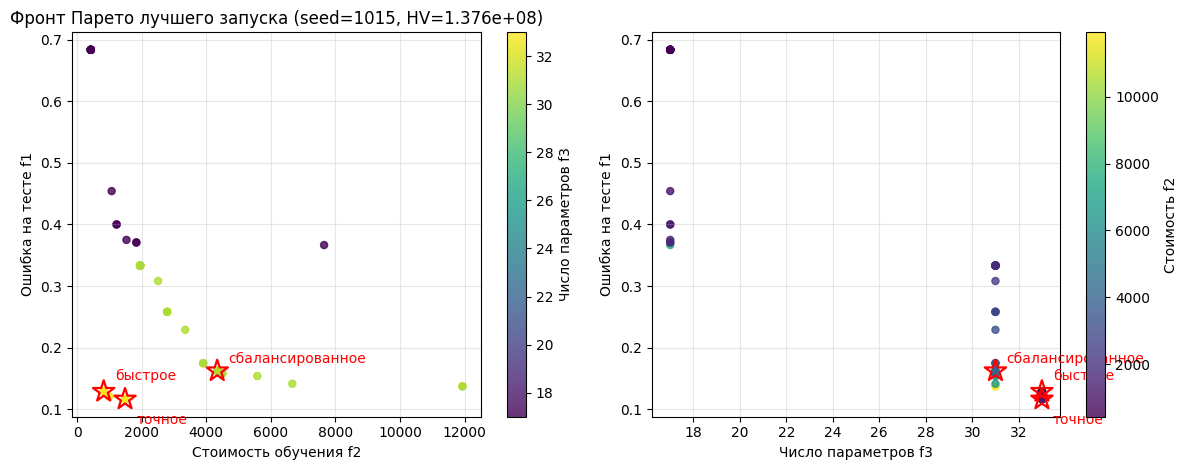

,solution,hidden,lr,epochs,l2,batch_size,f1_error,f2_cost,f3_params,train_ms
0,быстрое,0,0.034939,5,0.030058,128,0.129167,825.0,33,0.6
1,сбалансированное,2,0.100000,28,0.006315,128,0.162500,4340.0,31,3.4
2,точное,0,0.015219,9,0.017743,128,0.116667,1485.0,33,0.8


In [7]:
best_name = "NSGAII_base"
best_row = max(all_results[best_name], key=lambda r: r["hypervolume"])
best_seed = best_row["seed"]
best_result = tn.run_method(data, tn.GAConfig(seed=best_seed, method="nsga2"))
front = np.array(best_result["front_objectives"])
ref = np.array(tn.reference_point(data))
# характерные решения выбираются среди содержательных точек фронта:
# «быстрое» и «сбалансированное» ищутся лишь среди решений с ошибкой
# не более чем на 10 и 5 процентных пунктов хуже лучшей на фронте
f1_min = front[:, 0].min()
accurate = int(np.argmin(front[:, 0]))
fast_pool = np.flatnonzero(front[:, 0] <= f1_min + 0.10)
fast = int(fast_pool[np.argmin(front[fast_pool, 1])])
# сбалансированное решение — ближайшее к утопической точке в координатах,
# нормированных по размаху самого фронта (опорная точка слишком велика по f2
# и обесценивала бы различия стоимости)
span = front.max(axis=0) - front.min(axis=0)
norm = (front - front.min(axis=0)) / np.where(span > 0, span, 1.0)
bal_pool = np.flatnonzero(front[:, 0] <= f1_min + 0.05)
balanced = int(bal_pool[np.argmin(np.linalg.norm(norm[bal_pool], axis=1))])
indices = {
    "быстрое": fast,
    "сбалансированное": balanced,
    "точное": accurate,
}

fig, axes = plt.subplots(1, 2, figsize=(12, 4.8))
for ax, (j, xlabel) in zip(axes, [(1, "Стоимость обучения f2"), (2, "Число параметров f3")]):
    sc = ax.scatter(front[:, j], front[:, 0], c=front[:, 3 - j], cmap="viridis", s=26, alpha=0.8)
    for label, i in indices.items():
        ax.scatter(front[i, j], front[i, 0], marker="*", s=260, edgecolor="red", facecolor="none", linewidth=1.6)
        offsets = {"быстрое": (8, 8), "сбалансированное": (8, 6), "точное": (8, -18)}
        ax.annotate(label, (front[i, j], front[i, 0]), textcoords="offset points",
                    xytext=offsets[label], fontsize=10, color="red")
    ax.set_xlabel(xlabel)
    ax.set_ylabel("Ошибка на тесте f1")
    ax.grid(alpha=0.3)
    fig.colorbar(sc, ax=ax, label="Число параметров f3" if j == 1 else "Стоимость f2")
axes[0].set_title(f"Фронт Парето лучшего запуска (seed={best_seed}, HV={best_row['hypervolume']:.4g})")
fig.tight_layout()
fig.savefig(PLOTS_DIR / "pareto_front.png", dpi=150)
plt.show()

rows = []
front_table = pd.DataFrame(front, columns=["f1_error", "f2_cost", "f3_params"])
front_table.to_csv(RESULTS_DIR / "best_front.csv", index=False)
for label, i in indices.items():
    params = tn.decode(np.array(best_result["front_genomes"][i]))
    *_, seconds = tn.train_and_eval(params, data)
    rows.append({
        "solution": label, "hidden": params["hidden"], "lr": params["lr"],
        "epochs": params["epochs"], "l2": params["l2"], "batch_size": params["batch_size"],
        "f1_error": front[i, 0], "f2_cost": front[i, 1], "f3_params": int(front[i, 2]),
        "train_ms": round(seconds * 1000, 1),
    })
representatives = pd.DataFrame(rows)
representatives.to_csv(RESULTS_DIR / "representative_solutions.csv", index=False)
representatives

## Как интерпретировать результаты

- **NSGA-II против случайного поиска** при равном бюджете показывает, строит ли эволюция лучший фронт, чем простая выборка.
- **NSGA-II против взвешенной суммы** показывает цену свёртки: однокритериальный ГА оптимизирует одну точку компромисса, и его архив покрывает фронт хуже, чем популяция, управляемая Парето-доминированием.
- **Влияние факторов** (размер популяции, вероятность мутации) читается по различиям серий `NSGAII_small_pop` и `NSGAII_high_mutation` с базовой: меняется ровно один параметр.
- **Фронт лучшего запуска** и три характерных решения отвечают требованию содержательного анализа компромиссов: каждая точка фронта — осмысленный вариант настройки модели.